# 22 · 概率评分、可靠性与校准审计

第18章保留总览；本章单独深入一个问题。正式200k实验不覆盖，教学训练使用独立共享记录。

## 先预测：排序正确的概率会准确吗？

AUC只关心正负样本排序；logloss对过度自信错误惩罚很大；Brier是概率的平方误差。三者回答不同问题。校准要求同类预测概率附近的真实点击率相匹配，不能仅看可靠性曲线是否“好看”。

本章使用正式实验保存的真实逐曝光预测，明细仅留本机。基模型与样本固定，先看形状，再重新拟合同一预定sigmoid到独立calibration，核对audit结果；不新增audit选型。

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'reclab').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from reclab.ads import latest, load_data, split_groups, NUM, CAT, FEATURES
from reclab.paths import ARTIFACTS
from reclab.probability import evaluate
preview=ARTIFACTS/'notebook-previews';preview.mkdir(parents=True,exist_ok=True)
receipt,result=latest();folder=ARTIFACTS/'experiments/ads'/receipt['run_id']
data=np.load(folder/'predictions.npz',allow_pickle=False)
y=data['label'];raw=data[result['selected_base']];cal=data['split']==2;audit=data['split']==3
print('Probability vector:',raw.shape,'calibration:',int(cal.sum()),'audit:',int(audit.sum()))
print('Actual audit positives:',int(y[audit].sum()))

Probability vector: (200000,) calibration: 30153 audit: 29928
Actual audit positives: 992


## 概率损失的手算检查

对真实标签y∈{0,1}，logloss=−[y log(p)+(1−y)log(1−p)]。Brier=(p−y)²。下面两个样本明确为构造张量，p=.25/.75时手算应等于−log(.75)与.0625；换成同排序但更极端的概率，正确时可能更好，错误时可能付出更大代价。

先写出预期，再执行断言。这只能验证实现，不能替代真实评估。

In [2]:
toy_y=np.array([0,1]);toy_p=np.array([.25,.75])
r=evaluate(toy_y,toy_p)
assert np.isclose(r['logloss'],-np.log(.75)) and np.isclose(r['brier'],.0625)
for name,p in [('moderate',toy_p),('confident_correct',np.array([.01,.99])),('confident_wrong',np.array([.99,.01]))]:
 print(name,{k:evaluate(toy_y,p)[k] for k in ['auc','logloss','brier']})

moderate {'auc': 1.0, 'logloss': 0.2876820724517809, 'brier': 0.0625}
confident_correct {'auc': 1.0, 'logloss': 0.01005033585350145, 'brier': 0.00010000000000000014}
confident_wrong {'auc': 0.0, 'logloss': 4.605170185988091, 'brier': 0.9801}


## 真正执行：同基模型，重新拟合同一sigmoid

拟合输入为logit(p)的[Ncal,1]矩阵，只用calibration标签。逻辑回归C=1e6是预定近似无正则映射，不利用audit选择超参数。正斜率映射保留排序；若负斜率则反转，因此不能预设AUC必然不变。当前run结果应与保存预测重合。

不要因本次audit轻微改善就选择部署sigmoid；配对区间跨零，结论应保留不确定性。

In [3]:
from sklearn.linear_model import LogisticRegression
from reclab.ads import logit
mapper=LogisticRegression(C=1e6,solver='lbfgs',max_iter=200).fit(logit(raw[cal])[:,None],y[cal])
p=mapper.predict_proba(logit(raw[audit])[:,None])[:,1]
assert np.allclose(p,data['selected_sigmoid'][audit],atol=1e-10)
for name,prob in [('raw',raw[audit]),('refit_fixed_sigmoid',p),('stored_isotonic',data['selected_isotonic'][audit])]:
 r=evaluate(y[audit],prob);print(name,{k:r[k] for k in ['auc','logloss','brier','ece']})
print(result['paired_sigmoid'])

raw {'auc': 0.7063291304168487, 'logloss': 0.1360293933130953, 'brier': 0.031221289955195537, 'ece': 0.001738314050279206}
refit_fixed_sigmoid {'auc': 0.7063291304168487, 'logloss': 0.13596808940352492, 'brier': 0.031218897836043032, 'ece': 0.0011488903239790385}
stored_isotonic {'auc': 0.7030639468805462, 'logloss': 0.1364371767207884, 'brier': 0.0313022514243036, 'ece': 0.0011632039192470336}
{'calibrated_minus_raw_logloss': -6.130390957040765e-05, 'iid_row_bootstrap_95': [-0.00016953362229380587, 6.253575759107997e-05], 'replicates': 300, 'limitation': 'conditional on fitted models; repeated/related rows and one shard limit independence and generalization'}


## 只改一个变量：ECE分箱数

ECE不是proper scoring rule，分箱边界与样本量会改变结果。先预测把5箱改成20箱会怎样，再保持完全相同的预测和标签，分别计算。观察每箱count：一个高概率箱只有一两个样本时，连线的起伏不能解释成稳定的人群规律。

不依据audit ECE挑选分箱或模型。箱数在这里是度量敏感性练习，正式结果仍用预定10箱。

,bins,ece
0,5,0.001149
1,10,0.001149
2,20,0.001376


,bin,count,mean_probability,click_rate
0,0,28639,0.029438,0.028947
1,1,1216,0.130528,0.116776
2,2,67,0.230115,0.283582
3,3,6,0.330736,0.333333


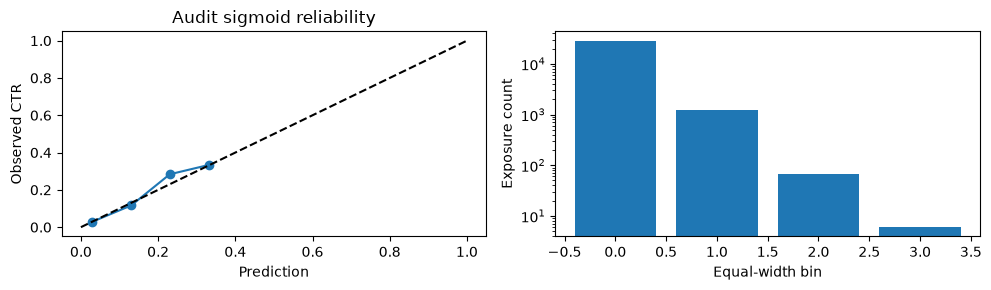

In [4]:
display(pd.DataFrame([{'bins':b,'ece':evaluate(y[audit],p,bins=b)['ece']} for b in [5,10,20]]))
r=evaluate(y[audit],p,bins=10);bins=pd.DataFrame(r['reliability']);display(bins)
fig,axes=plt.subplots(1,2,figsize=(10,3));axes[0].plot(bins.mean_probability,bins.click_rate,'o-');axes[0].plot([0,1],[0,1],'k--')
axes[0].set(xlabel='Prediction',ylabel='Observed CTR',title='Audit sigmoid reliability');axes[1].bar(bins.bin,bins['count']);axes[1].set(xlabel='Equal-width bin',ylabel='Exposure count',yscale='log')
fig.tight_layout();fig.savefig(preview/'22_calibration.png',dpi=130);plt.show()

## 分段与结论边界

未见类别段和缺失段的点击基率不同，不能仅根据logloss的绝对高低判定模型对谁“更差”。至少同时看样本数、基率、预测均值和损失。当前字段匿名，无法进行人口属性公平性评估；抽样率未披露，也不能恢复总体CTR。

练习：只改变某一个真实样本的输入，在工作台检查概率变化；不要把输入反事实叫作真实因果影响。下面的聚合分段仍来自预定audit，不做新增选型。

In [5]:
display(pd.DataFrame([{'segment':s['segment'],'n':s['raw']['n'],'CTR':s['raw']['click_rate'],'raw_mean':s['raw']['mean_probability'],'sigmoid_mean':s['sigmoid']['mean_probability'],'raw_loss':s['raw']['logloss'],'sigmoid_loss':s['sigmoid']['logloss']} for s in result['segments']]))
print('Conclusion: small sigmoid loss change is uncertain; isotonic negative result remains. Population calibration is unidentified.')

,segment,n,CTR,raw_mean,sigmoid_mean,raw_loss,sigmoid_loss
0,low_numeric_missing,17016,0.036495,0.035931,0.037111,0.147043,0.146935
1,high_numeric_missing,12912,0.028733,0.028715,0.030027,0.121515,0.121515
2,any_unseen_category,11668,0.035996,0.034161,0.035395,0.146929,0.146712
3,all_categories_seen,18260,0.031325,0.031960,0.033198,0.129065,0.129103


Conclusion: small sigmoid loss change is uncertain; isotonic negative result remains. Population calibration is unidentified.
